In [1]:
import GPy, GPyOpt
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def f_u(x):
    return x**5 + 0.1 + 0.3 * np.random.randn()

bounds = [{'name': 'var_1', 'type': 'continuous', 'domain': (0,1)}]
myBopt = GPyOpt.methods.BayesianOptimization(f=f_u, domain=bounds, acquisition_type='EI', exact_feval = False, initial_design_numdata=100, normalize_Y=False)
max_iter = 0; max_time = 60; eps = 10e-6

In [3]:
myBopt.run_optimization(max_iter, eps)
myBopt._update_model()
model = myBopt.model.model

In [4]:
x_grid = np.arange(0, 1, 0.001)
x_grid = x_grid.reshape(len(x_grid),1)
m, v = model.predict(x_grid)

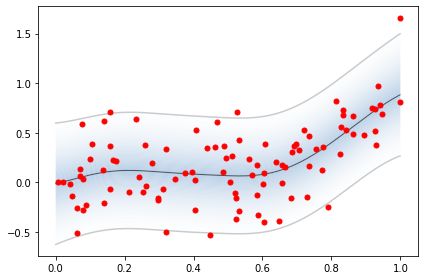

In [5]:
model.plot_density([0,1], alpha=.5)
plt.plot(x_grid, m, 'k-',lw=1,alpha = 0.6)
plt.plot(x_grid, m-1.96*np.sqrt(v), 'k-', alpha = 0.2)
plt.plot(x_grid, m+1.96*np.sqrt(v), 'k-', alpha=0.2)

Xdata, Ydata = myBopt.get_evaluations()
plt.plot(Xdata, Ydata, 'r.', markersize=10)
plt.show()

[[0.96490306 0.25859084 0.77999655]]
[[0.96490306 0.25859084 0.77999655]]


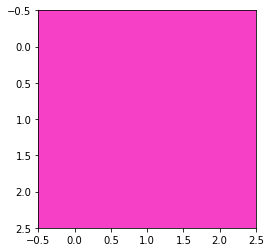

[[0.69650326 0.20887168 0.3231735 ]]
[[0.69650326 0.20887168 0.3231735 ]]


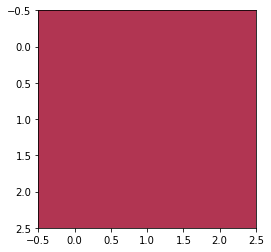

[[0.84462    0.75892061 0.29242702]]
[[0.84462    0.75892061 0.29242702]]


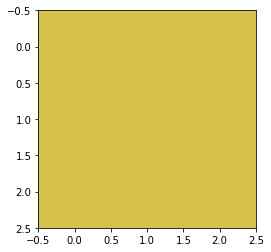

[[0.14862477 0.46288821 0.83517911]]
[[0.14862477 0.46288821 0.83517911]]


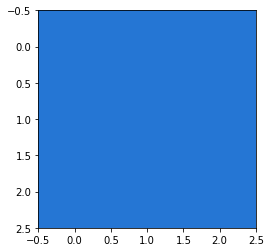

[[0.05244506 0.79213795 0.87116696]]
[[0.05244506 0.79213795 0.87116696]]


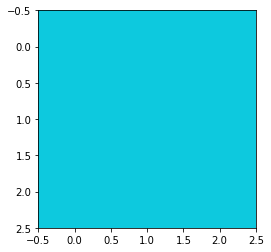

[[0.93594595 0.83806894 0.43624894]]
[[0.93594595 0.83806894 0.43624894]]


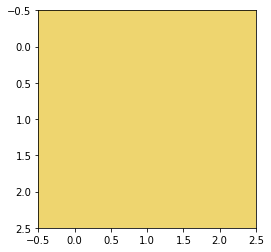

[[0.01564865 0.12821268 0.70437985]]
[[0.01564865 0.12821268 0.70437985]]


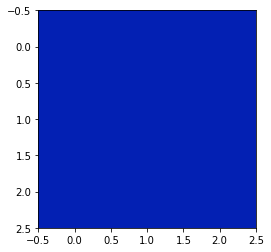

[[0.56864563 0.37346082 0.71179786]]
[[0.56864563 0.37346082 0.71179786]]


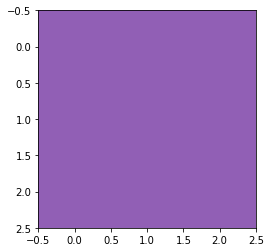

[[0.07908745 0.47202809 0.20631505]]
[[0.07908745 0.47202809 0.20631505]]


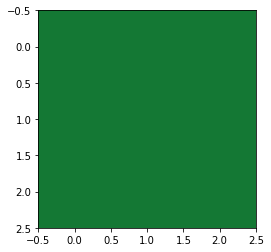

[[0.65130133 0.05986061 0.78078623]]
[[0.65130133 0.05986061 0.78078623]]


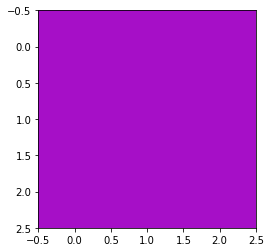

[0.34798724 0.90363843 0.2182565 ]
[0.34798724 0.90363843 0.2182565 ]


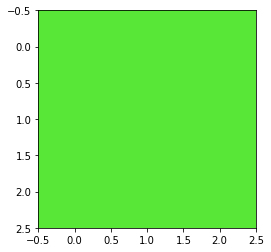

[0.09636023 0.55252161 0.59857068]
[0.09636023 0.55252161 0.59857068]


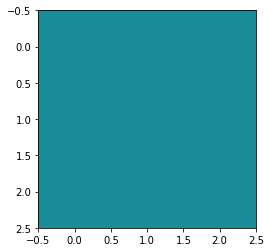

bo:  <GPyOpt.methods.bayesian_optimization.BayesianOptimization object at 0x163708640>
[[0.96490306 0.25859084 0.77999655]
 [0.69650326 0.20887168 0.3231735 ]
 [0.84462    0.75892061 0.29242702]
 [0.14862477 0.46288821 0.83517911]
 [0.05244506 0.79213795 0.87116696]
 [0.93594595 0.83806894 0.43624894]
 [0.01564865 0.12821268 0.70437985]
 [0.56864563 0.37346082 0.71179786]
 [0.07908745 0.47202809 0.20631505]
 [0.65130133 0.05986061 0.78078623]] [[-1.]
 [-1.]
 [-1.]
 [-1.]
 [-1.]
 [-1.]
 [-1.]
 [-1.]
 [-1.]
 [-1.]]


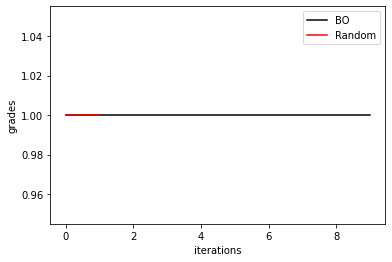

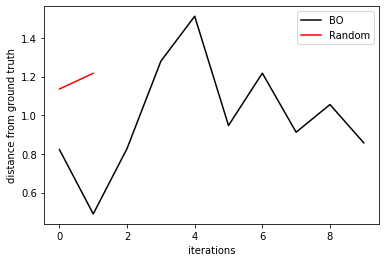

In [9]:
def f_u(x):
    print(x)
    plt.figure(1)
    print(x)
    im = x.reshape(1, 1, 3).repeat(3, axis=0).repeat(3, axis=1)
    plt.imshow(im)
    plt.show(block=False)
    while True:
        res = input('Grade? (0 to 5) ')
        if res in ['0', '1', '2', '3', '4', '5']:
            res = int(res)
            plt.close(1)
            return res


def run_bo(max_iter):
    bounds = [{'name': 'var_1', 'type': 'continuous', 'domain': (0, 1)},
              {'name': 'var_2', 'type': 'continuous', 'domain': (0, 1)},
              {'name': 'var_3', 'type': 'continuous', 'domain': (0, 1)}]
    myBopt = GPyOpt.methods.BayesianOptimization(
        f=f_u, domain=bounds,
        acquisition_type='MPI',
        exact_feval=False,
        eps=1e-6,
        normalize_Y=False,
        initial_design_numdata=10,
        maximize=True)
    myBopt.run_optimization(max_iter=max_iter - 10)

    return myBopt


def run_random(max_iter):
    xs = np.zeros((max_iter, 3))
    ys = np.zeros((max_iter,))

    for i in range(max_iter):
        xs[i, :] = np.random.rand(3)

        ys[i] = f_u(xs[i, :])

    return xs, ys


if __name__ == "__main__":
    n_iter = 2
    # run BO
    bo = run_bo(n_iter)
    # run random for comparison
    n_iter = 2
    ra = run_random(n_iter)
    print('bo: ',bo)

    bo_xs, bo_ys = bo.get_evaluations()
    print(bo_xs, bo_ys)
    ra_xs, ra_ys = ra

    # one can investigate these to see how good colors were found and compare
    # to a ground truth color

    plt.plot(-bo_ys, 'k-', label='BO')
    plt.plot(ra_ys, 'r-', label='Random')
    plt.xlabel('iterations')
    plt.ylabel('grades')
    plt.legend()
    plt.show()

    # let's say ground truth color was red
    x_gt = np.array([1.0, 0.0, 0.0])

    plt.plot(np.sqrt(np.sum((bo_xs - x_gt)**2, 1)), 'k-', label='BO')
    plt.plot(np.sqrt(np.sum((ra_xs - x_gt)**2, 1)), 'r-', label='Random')
    plt.xlabel('iterations')
    plt.ylabel('distance from ground truth')
    plt.legend()
    plt.show()